# Football AI

Let's build a Football AI system to dig deeper into match stats!

![football AI diagram](https://media.roboflow.com/notebooks/examples/football-ai-diagram.png)

## Before you start

### Configure your API keys

- Open your [`HuggingFace Settings`](https://huggingface.co/settings) page. Click `Access Tokens` then `New Token` to generate new token.
- Go to your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑).
    - Store HuggingFace Access Token under the name `HF_TOKEN`.
    - Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

In [1]:
import os
from google.colab import userdata

for name in [
    "HF_TOKEN",
    "ROBOFLOW_API_KEY",
    "MODAL_TOKEN_ID",
    "MODAL_TOKEN_SECRET",
]:
    os.environ[name] = userdata.get(name).strip()

print("Đã nạp đủ 4 thông tin xác thực.")

Đã nạp đủ 4 thông tin xác thực.


### Select the runtime

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Edit` -> `Notebook settings` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [ ]:
!nvidia-smi

Fri Oct 30 02:17:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Install dependencjes

**Note:** Let's install the `inference-gpu` library, which will be used to efficiently run our object detection and keypoint detection models on GPUs.

In [2]:
!pip install -q modal gdown supervision

In [3]:
!pip install -q trackers

**Note:** Let's make sure we have the latest features in the supervision library by installing version `0.23.0` or higher.

In [4]:
!pip list | grep supervision

supervision                           0.31.3


**Note:** Let's download a few sample videos from the [DFL - Bundesliga Data Shootout](https://www.kaggle.com/competitions/dfl-bundesliga-data-shootout) Kaggle competition using gdown.



In [5]:
!gdown -O "0bfacc_0.mp4" "https://drive.google.com/uc?id=12TqauVZ9tLAv8kWxTTBFWtgt2hNQ4_ZF"
!gdown -O "2e57b9_0.mp4" "https://drive.google.com/uc?id=19PGw55V8aA6GZu5-Aac5_9mCy3fNxmEf"
!gdown -O "08fd33_0.mp4" "https://drive.google.com/uc?id=1OG8K6wqUw9t7lp9ms1M48DxRhwTYciK-"
!gdown -O "573e61_0.mp4" "https://drive.google.com/uc?id=1yYPKuXbHsCxqjA9G-S6aeR2Kcnos8RPU"
!gdown -O "121364_0.mp4" "https://drive.google.com/uc?id=1vVwjW1dE1drIdd4ZSILfbCGPD4weoNiu"

Downloading...
From: https://drive.google.com/uc?id=12TqauVZ9tLAv8kWxTTBFWtgt2hNQ4_ZF
To: /content/0bfacc_0.mp4
100% 19.9M/19.9M [00:00<00:00, 85.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=19PGw55V8aA6GZu5-Aac5_9mCy3fNxmEf
To: /content/2e57b9_0.mp4
100% 21.1M/21.1M [00:00<00:00, 48.9MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OG8K6wqUw9t7lp9ms1M48DxRhwTYciK-
To: /content/08fd33_0.mp4
100% 19.9M/19.9M [00:00<00:00, 111MB/s]
Downloading...
From: https://drive.google.com/uc?id=1yYPKuXbHsCxqjA9G-S6aeR2Kcnos8RPU
To: /content/573e61_0.mp4
100% 18.9M/18.9M [00:00<00:00, 149MB/s]
Downloading...
From: https://drive.google.com/uc?id=1vVwjW1dE1drIdd4ZSILfbCGPD4weoNiu
To: /content/121364_0.mp4
100% 17.2M/17.2M [00:00<00:00, 89.3MB/s]


In [6]:
import os
import sys
import modal

app = modal.App("football-ai")

python_version = f"{sys.version_info.major}.{sys.version_info.minor}"

modal_image = (
    modal.Image.from_registry(
        "nvidia/cuda:12.4.1-cudnn-devel-ubuntu22.04",
        add_python=python_version,
    )
    .entrypoint([])
    .apt_install(
        "git",
        "ffmpeg",
        "libgl1",
        "libglib2.0-0",
        "build-essential",
        "clang",
    )
    .env({
        "CUDA_ROOT": "/usr/local/cuda",
        "CUDA_HOME": "/usr/local/cuda",
    })
    .pip_install("gdown", "inference-gpu")
    .pip_install("git+https://github.com/roboflow/sports.git")
    .pip_install("inference-models[onnx-cu12]")
    # Chỉ giữ một bản ONNX Runtime để tránh trùng module.
    .run_commands(
        "python -m pip uninstall -y onnxruntime onnxruntime-gpu",
        "python -m pip install 'onnxruntime-gpu[cuda,cudnn]'",
    )
)

runtime_secrets = modal.Secret.from_dict({
    "HF_TOKEN": os.environ["HF_TOKEN"],
    "ROBOFLOW_API_KEY": os.environ["ROBOFLOW_API_KEY"],
})

video_volume = modal.Volume.from_name(
    "football-ai-videos",
    create_if_missing=True,
    version=2,
)

## ball, player, goalkeeper and referee detection

In [7]:
PLAYER_DETECTION_MODEL_ID = "football-players-detection-3zvbc/11"

@app.function(
    image=modal_image,
    gpu="L40S",
    secrets=[runtime_secrets],
    timeout=600,
)
def check_player_model(model_id: str):
    import os
    import subprocess

    # Bỏ cấu hình ép provider cũ, trước khi import inference.
    os.environ.pop("ONNXRUNTIME_EXECUTION_PROVIDERS", None)

    try:
        import onnxruntime as ort

        # Nạp thư viện CUDA/cuDNN cài kèm ONNX Runtime.
        if hasattr(ort, "preload_dlls"):
            ort.preload_dlls()

        gpu = subprocess.check_output(
            [
                "nvidia-smi",
                "--query-gpu=name",
                "--format=csv,noheader",
            ],
            text=True,
        ).strip()

        providers = ort.get_available_providers()
        print("GPU:", gpu)
        print("ONNX Runtime:", ort.__version__)
        print("Available providers:", providers)

        if "CUDAExecutionProvider" not in providers:
            raise RuntimeError(
                "ONNX Runtime chưa nhận CUDAExecutionProvider."
            )

        from inference import get_model

        model = get_model(
            model_id=model_id,
            api_key=os.environ["ROBOFLOW_API_KEY"],
        )

        print("Đã tải model:", model_id)

        return {
            "gpu": gpu,
            "providers": providers,
            "model_id": model_id,
        }

    except Exception as exc:
        # Trả lỗi dạng chuẩn để Colab đọc được.
        raise RuntimeError(
            f"{type(exc).__name__}: {exc}"
        ) from None

In [8]:
with modal.enable_output():
    with app.run():
        status = check_player_model.remote(
            PLAYER_DETECTION_MODEL_ID
        )

print(status)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-jhy4ASF2g2NFWy099e3UZ8
✓ Created objects.
└── ✓ Created Function check_player_model.
GPU: NVIDIA L40S
ONNX Runtime: 1.31.1
Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Use pip

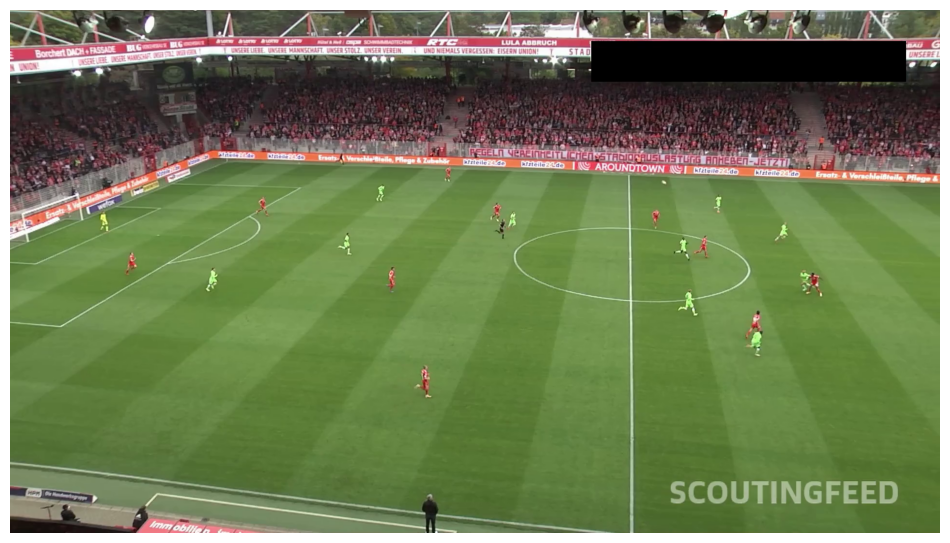

In [9]:
import supervision as sv

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

sv.plot_image(frame)

In [10]:
@app.function(
    image=modal_image,
    gpu="L40S",
    secrets=[runtime_secrets],
    timeout=600,
)
def detect_frame_modal(image_bytes: bytes, model_id: str):
    import os
    import cv2
    import numpy as np
    import onnxruntime as ort

    os.environ.pop("ONNXRUNTIME_EXECUTION_PROVIDERS", None)

    if hasattr(ort, "preload_dlls"):
        ort.preload_dlls()

    try:
        from inference import get_model

        model = get_model(
            model_id=model_id,
            api_key=os.environ["ROBOFLOW_API_KEY"],
        )

        remote_frame = cv2.imdecode(
            np.frombuffer(image_bytes, dtype=np.uint8),
            cv2.IMREAD_COLOR,
        )
        if remote_frame is None:
            raise ValueError("Không giải mã được ảnh đầu vào")

        result = model.infer(remote_frame, confidence=0.3)[0]

        # Trả dữ liệu thông thường về Colab.
        return (
            result.model_dump(mode="json", by_alias=True)
            if hasattr(result, "model_dump")
            else result
        )
    except Exception as exc:
        raise RuntimeError(f"{type(exc).__name__}: {exc}") from None

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-JRaklyXEgkgJCrOUYANQPs
✓ Created objects.
├── ✓ Created Function check_player_model.
└── ✓ Created Function detect_frame_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Use pip install 'inference[sam]' to install missing requirements.To suppress this warning, set CORE_MO

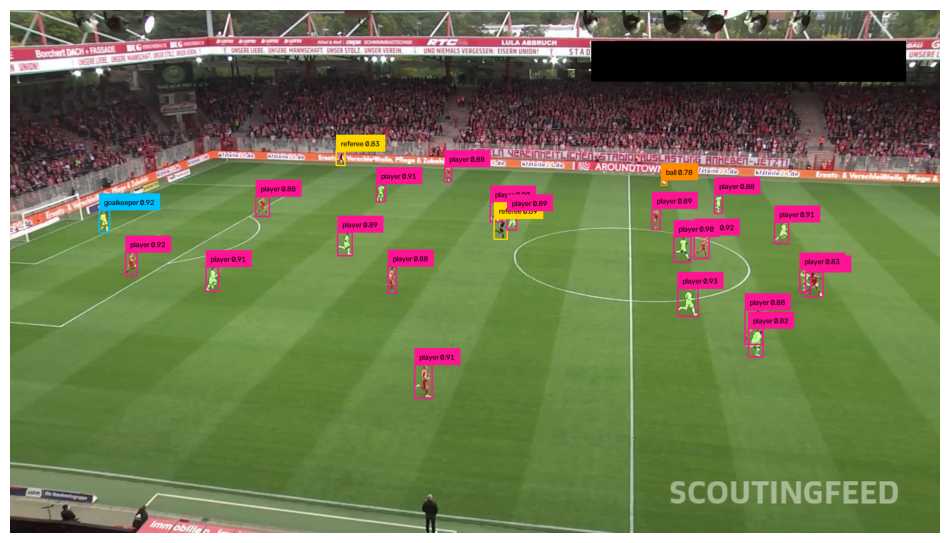

In [11]:
import supervision as sv
import cv2

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"

box_annotator = sv.BoxAnnotator(
    color=sv.ColorPalette.from_hex(['#FF8C00', '#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
    color=sv.ColorPalette.from_hex(['#FF8C00', '#00BFFF', '#FF1493', '#FFD700']),
    text_color=sv.Color.from_hex('#000000')
)

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

# PNG giữ nguyên chất lượng frame khi gửi sang Modal.
ok, encoded_frame = cv2.imencode(".png", frame)
assert ok, "Không mã hóa được frame"

with modal.enable_output():
    with app.run():
        result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            PLAYER_DETECTION_MODEL_ID,
        )
# Chuẩn hóa tên trường để tương thích với Supervision.
for prediction in result.get("predictions", []):
    if "class" not in prediction and "class_name" in prediction:
        prediction["class"] = prediction["class_name"]

detections = sv.Detections.from_inference(result)

labels = [
    f"{class_name} {confidence:.2f}"
    for class_name, confidence
    in zip(detections["class_name"], detections.confidence)
]

annotated_frame = frame.copy()

annotated_frame = box_annotator.annotate(
    scene=annotated_frame,
    detections=detections,
)

annotated_frame = label_annotator.annotate(
    scene=annotated_frame,
    detections=detections,
    labels=labels,
)

sv.plot_image(annotated_frame)

## video game style visualization

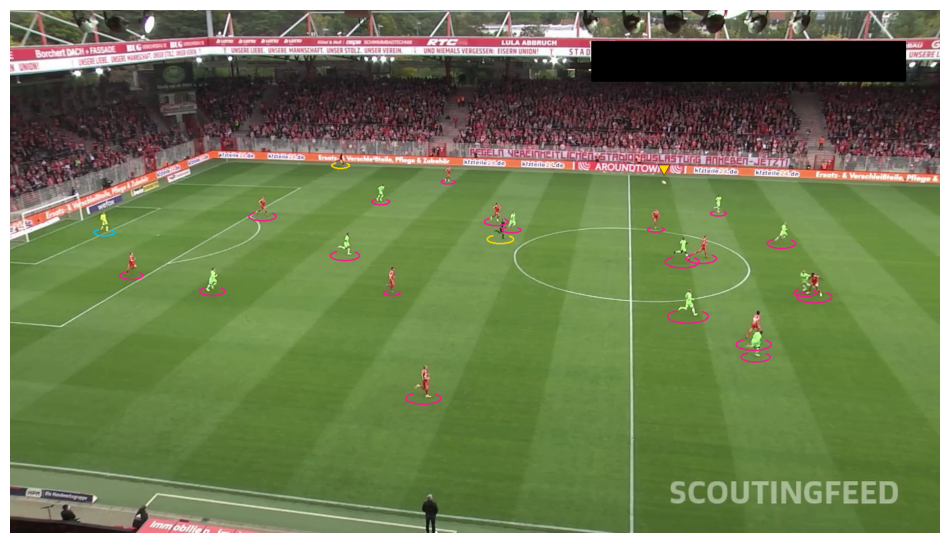

In [12]:
import supervision as sv

BALL_ID = 0

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex([
        "#00BFFF", "#FF1493", "#FFD700"
    ]),
    thickness=2,
)

triangle_annotator = sv.TriangleAnnotator(
    color=sv.Color.from_hex("#FFD700"),
    base=25,
    height=21,
    outline_thickness=1,
)

# Dùng lại frame và result từ cell detection trước.
for prediction in result.get("predictions", []):
    if "class" not in prediction and "class_name" in prediction:
        prediction["class"] = prediction["class_name"]

# Tạo lại detections để các thay đổi dưới đây không ảnh hưởng cell trước.
detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(
    xyxy=ball_detections.xyxy,
    px=10,
)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(
    threshold=0.5,
    class_agnostic=True,
)

# Đổi ID 1, 2, 3 thành 0, 1, 2 để khớp palette 3 màu.
all_detections.class_id = all_detections.class_id - 1

annotated_frame = frame.copy()

annotated_frame = ellipse_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
)

annotated_frame = triangle_annotator.annotate(
    scene=annotated_frame,
    detections=ball_detections,
)

sv.plot_image(annotated_frame)

## player tracking

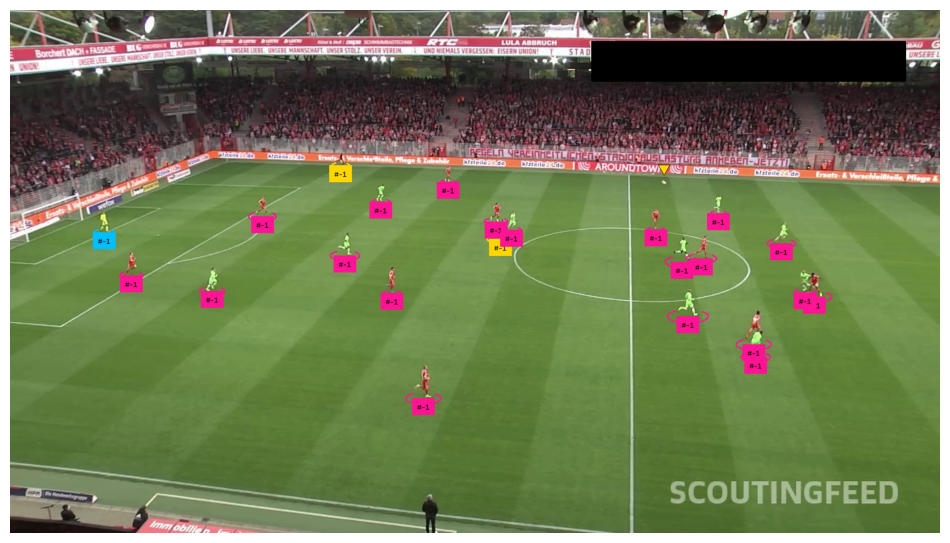

In [13]:
import supervision as sv
from trackers import ByteTrackTracker

BALL_ID = 0

palette = sv.ColorPalette.from_hex([
    "#00BFFF", "#FF1493", "#FFD700"
])

ellipse_annotator = sv.EllipseAnnotator(
    color=palette,
    thickness=2,
)

label_annotator = sv.LabelAnnotator(
    color=palette,
    text_color=sv.Color.from_hex("#000000"),
    text_position=sv.Position.BOTTOM_CENTER,
)

triangle_annotator = sv.TriangleAnnotator(
    color=sv.Color.from_hex("#FFD700"),
    base=25,
    height=21,
    outline_thickness=1,
)

tracker = ByteTrackTracker(minimum_consecutive_frames=1)

# Dùng lại frame và result từ lần inference trước.
for prediction in result.get("predictions", []):
    if "class" not in prediction and "class_name" in prediction:
        prediction["class"] = prediction["class_name"]

detections = sv.Detections.from_inference(result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(
    xyxy=ball_detections.xyxy,
    px=10,
)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(
    threshold=0.5,
    class_agnostic=True,
)
all_detections.class_id = all_detections.class_id - 1

all_detections = tracker.update(all_detections)

labels = [
    f"#{tracker_id}"
    for tracker_id in all_detections.tracker_id
]

annotated_frame = frame.copy()

annotated_frame = ellipse_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
)
annotated_frame = label_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
    labels=labels,
)
annotated_frame = triangle_annotator.annotate(
    scene=annotated_frame,
    detections=ball_detections,
)

sv.plot_image(annotated_frame)

## split players into teams

![football AI diagram](https://media.roboflow.com/notebooks/examples/football-ai-team-clustering.png)

**Note:** Before training our player clustering model, we need to gather training data. To do this, we'll sample one frame per second, detect players within those frames, and then crop them out.

In [14]:
from pathlib import Path

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"
assert Path(SOURCE_VIDEO_PATH).is_file(), "Không tìm thấy video"

with video_volume.batch_upload(force=True) as upload:
    upload.put_file(
        SOURCE_VIDEO_PATH,
        "/inputs/121364_0.mp4",
    )

print("Đã upload video sang Modal.")

Đã upload video sang Modal.


In [15]:
@app.function(
    image=modal_image,
    gpu="L40S",
    secrets=[runtime_secrets],
    volumes={"/storage": video_volume},
    timeout=3600,
)
def collect_player_crops_modal(
    model_id: str,
    stride: int = 30,
    player_id: int = 2,
):
    import os
    import cv2
    import supervision as sv
    import onnxruntime as ort
    from tqdm import tqdm

    os.environ.pop("ONNXRUNTIME_EXECUTION_PROVIDERS", None)

    if hasattr(ort, "preload_dlls"):
        ort.preload_dlls()

    try:
        from inference import get_model

        video_volume.reload()

        model = get_model(
            model_id=model_id,
            api_key=os.environ["ROBOFLOW_API_KEY"],
        )

        frame_generator = sv.get_video_frames_generator(
            source_path="/storage/inputs/121364_0.mp4",
            stride=stride,
        )

        encoded_crops = []

        for frame in tqdm(frame_generator, desc="Collecting crops"):
            result = model.infer(frame, confidence=0.3)[0]

            if hasattr(result, "model_dump"):
                result = result.model_dump(
                    mode="json",
                    by_alias=True,
                )

            detections = sv.Detections.from_inference(result)
            detections = detections.with_nms(
                threshold=0.5,
                class_agnostic=True,
            )
            detections = detections[
                detections.class_id == player_id
            ]

            for xyxy in detections.xyxy:
                crop = sv.crop_image(frame, xyxy)

                if crop is None or crop.size == 0:
                    continue

                ok, encoded = cv2.imencode(".png", crop)
                if ok:
                    encoded_crops.append(encoded.tobytes())

        print("Tổng số ảnh cầu thủ:", len(encoded_crops))
        return encoded_crops

    except Exception as exc:
        raise RuntimeError(
            f"{type(exc).__name__}: {exc}"
        ) from None

In [16]:
import cv2
import numpy as np

PLAYER_ID = 2
STRIDE = 30

with modal.enable_output():
    with app.run():
        encoded_crops = collect_player_crops_modal.remote(
            model_id=PLAYER_DETECTION_MODEL_ID,
            stride=STRIDE,
            player_id=PLAYER_ID,
        )

# Khôi phục thành danh sách ảnh BGR như cell gốc.
crops = [
    cv2.imdecode(
        np.frombuffer(data, dtype=np.uint8),
        cv2.IMREAD_COLOR,
    )
    for data in encoded_crops
]

crops = [crop for crop in crops if crop is not None]
del encoded_crops

print("Số ảnh cầu thủ nhận được:", len(crops))

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-rx5tzxGfNQM114pHa72wsV
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
└── ✓ Created Function collect_player_crops_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Use pip install 'inference[sam]' to install missing

**Note:** Here's a sample (100 elements) of the crops we've gathered.

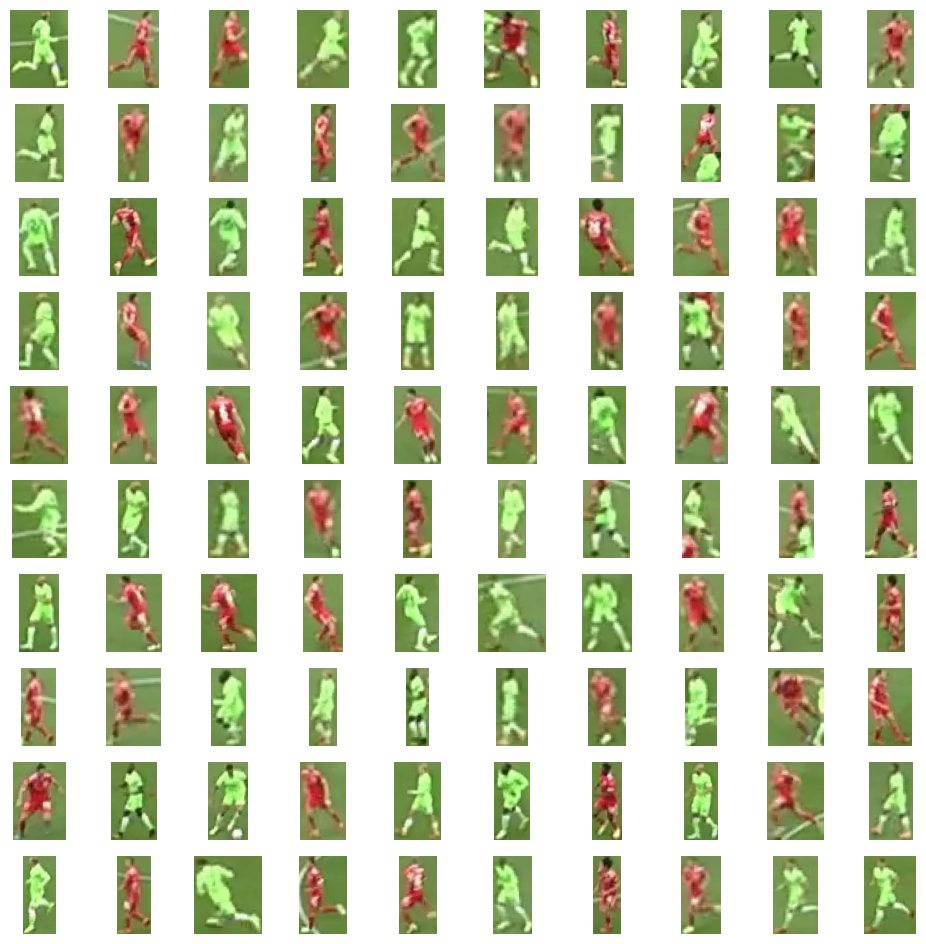

In [17]:
import math
import supervision as sv

preview_crops = crops[:100]

if not preview_crops:
    raise ValueError("Chưa thu được ảnh cầu thủ; kiểm tra kết quả cell trước.")

columns = min(10, len(preview_crops))
rows = math.ceil(len(preview_crops) / columns)

sv.plot_images_grid(
    preview_crops,
    grid_size=(rows, columns),
)

**Note:** Next, we'll run [SigLIP](https://huggingface.co/docs/transformers/en/model_doc/siglip) to calculate embeddings for each of the crops.

In [18]:
SIGLIP_MODEL_PATH = "google/siglip-base-patch16-224"

@app.function(
    image=modal_image,
    gpu="L40S",
    secrets=[runtime_secrets],
    timeout=1800,
)
def extract_embeddings_modal(
    crop_images: list[bytes],
    model_path: str,
    batch_size: int = 32,
):
    import io
    import torch
    from PIL import Image
    from tqdm import tqdm
    from transformers import AutoProcessor, SiglipVisionModel

    try:
        if not crop_images:
            raise ValueError("Danh sách crops đang rỗng.")

        if not torch.cuda.is_available():
            raise RuntimeError("PyTorch bên Modal chưa nhận CUDA.")

        print("GPU SigLIP:", torch.cuda.get_device_name(0))

        model = SiglipVisionModel.from_pretrained(
            model_path
        ).to("cuda").eval()

        processor = AutoProcessor.from_pretrained(model_path)

        embeddings_batches = []

        for start in tqdm(
            range(0, len(crop_images), batch_size),
            desc="Extracting embeddings",
        ):
            images = [
                Image.open(io.BytesIO(data)).convert("RGB")
                for data in crop_images[start:start + batch_size]
            ]

            inputs = processor(
                images=images,
                return_tensors="pt",
            ).to("cuda")

            with torch.inference_mode():
                outputs = model(**inputs)
                batch_embeddings = outputs.last_hidden_state.mean(dim=1)

            embeddings_batches.append(
                batch_embeddings.cpu()
            )

        return torch.cat(
            embeddings_batches,
            dim=0,
        ).numpy().tolist()

    except Exception as exc:
        raise RuntimeError(
            f"{type(exc).__name__}: {exc}"
        ) from None

In [19]:
import cv2
import numpy as np

BATCH_SIZE = 32

if not crops:
    raise ValueError("Danh sách crops đang rỗng.")

# crops hiện là các ảnh OpenCV dạng BGR.
# Mã hóa PNG để truyền sang Modal; không thay đổi biến crops.
crop_images = []

for index, crop in enumerate(crops):
    ok, encoded = cv2.imencode(".png", crop)

    if not ok:
        raise ValueError(f"Không mã hóa được crop thứ {index}")

    crop_images.append(encoded.tobytes())

# SigLIP chạy trên GPU L40S bên Modal.
with modal.enable_output():
    with app.run():
        embedding_rows = extract_embeddings_modal.remote(
            crop_images=crop_images,
            model_path=SIGLIP_MODEL_PATH,
            batch_size=BATCH_SIZE,
        )

# Giữ tên biến data như notebook gốc cho các cell tiếp theo.
data = np.asarray(embedding_rows, dtype=np.float32)

assert data.ndim == 2
assert data.shape[0] == len(crops)
assert np.isfinite(data).all(), "Embedding chứa NaN hoặc Infinity"

print("Số ảnh cầu thủ:", len(crops))
print("Kích thước embeddings:", data.shape)

del crop_images, embedding_rows

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-fucSzRl5YQYwXEZPe9cIEQ
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
└── ✓ Created Function extract_embeddings_modal.
GPU SigLIP: NVIDIA L40S

Loading weights: 100%|██████████| 208/208 [00:00<00:00, 4451.85it/s]
[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias

In [20]:
print("Số crops:", len(crops))
print("Kích thước data:", data.shape)

assert data.shape == (len(crops), 768)
assert np.isfinite(data).all()

print("Embeddings hợp lệ, có thể chạy cell tiếp theo.")

Số crops: 493
Kích thước data: (493, 768)
Embeddings hợp lệ, có thể chạy cell tiếp theo.


**Note:** Using [UMAP](https://github.com/lmcinnes/umap), we project our embeddings from `(N, 768)` to `(N, 3)` and then perform a two-cluster division using [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html).

In [21]:
!pip install -q umap-learn scikit-learn

In [22]:
import umap
from sklearn.cluster import KMeans

REDUCER = umap.UMAP(
    n_components=3,
    random_state=42,
)

CLUSTERING_MODEL = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10,
)

In [23]:
projections = REDUCER.fit_transform(data)
clusters = CLUSTERING_MODEL.fit_predict(projections)

print("Kích thước projections:", projections.shape)
print("Số crops mỗi nhóm:", np.bincount(clusters, minlength=2))

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Kích thước projections: (493, 3)
Số crops mỗi nhóm: [248 245]


**Note:** Here's an interactive visualization of our results. Click on a dot to display its associated crop.


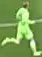
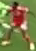
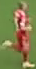
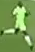
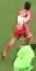
...
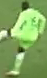
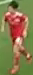
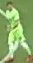
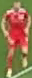
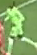

In [24]:
import plotly.graph_objects as go
import numpy as np
from typing import Dict, List
from IPython.display import display, HTML
import cv2
import json
from PIL import Image
import base64
from io import BytesIO


def pil_image_to_data_uri(image: Image.Image) -> str:
    buffered = BytesIO()
    image.save(buffered, format="PNG")
    img_str = base64.b64encode(buffered.getvalue()).decode("utf-8")
    return f"data:image/png;base64,{img_str}"


def display_projections(
    labels: np.ndarray,
    projections: np.ndarray,
    images: List[Image.Image],
    show_legend: bool = False,
    show_markers_with_text: bool = True
) -> None:
    image_data_uris = {f"image_{i}": pil_image_to_data_uri(image) for i, image in enumerate(images)}
    image_ids = np.array([f"image_{i}" for i in range(len(images))])

    unique_labels = np.unique(labels)
    traces = []
    for unique_label in unique_labels:
        mask = labels == unique_label
        customdata_masked = image_ids[mask]
        trace = go.Scatter3d(
            x=projections[mask][:, 0],
            y=projections[mask][:, 1],
            z=projections[mask][:, 2],
            mode='markers+text' if show_markers_with_text else 'markers',
            text=labels[mask],
            customdata=customdata_masked,
            name=str(unique_label),
            marker=dict(size=8),
            hovertemplate="<b>class: %{text}</b><br>image ID: %{customdata}<extra></extra>"
        )
        traces.append(trace)

    # Calculate shared range for cube appearance
    all_axes = projections
    min_val = np.min(all_axes)
    max_val = np.max(all_axes)
    padding = (max_val - min_val) * 0.05
    axis_range = [min_val - padding, max_val + padding]

    fig = go.Figure(data=traces)
    fig.update_layout(
        scene=dict(
            xaxis=dict(title='X', range=axis_range),
            yaxis=dict(title='Y', range=axis_range),
            zaxis=dict(title='Z', range=axis_range),
            aspectmode='cube'  # Ensures equal scaling
        ),
        width=1000,
        height=1000,
        showlegend=show_legend
    )

    plotly_div = fig.to_html(
        full_html=False,
        include_plotlyjs=True,
        div_id="scatter-plot-3d",
    )

    javascript_code = f"""
    <script>
        function displayImage(imageId) {{
            var imageElement = document.getElementById('image-display');
            var placeholderText = document.getElementById('placeholder-text');
            var imageDataURIs = {json.dumps(image_data_uris)};
            imageElement.src = imageDataURIs[imageId];
            imageElement.style.display = 'block';
            placeholderText.style.display = 'none';
        }}

        var chartElement = document.getElementById('scatter-plot-3d');

        chartElement.on('plotly_click', function(data) {{
            var customdata = data.points[0].customdata;
            displayImage(customdata);
        }});
    </script>
    """

    html_template = f"""
    <!DOCTYPE html>
    <html>
        <head>
            <style>
                #image-container {{
                    position: fixed;
                    top: 0;
                    left: 0;
                    width: 200px;
                    height: 200px;
                    padding: 5px;
                    border: 1px solid #ccc;
                    background-color: white;
                    z-index: 1000;
                    box-sizing: border-box;
                    display: flex;
                    align-items: center;
                    justify-content: center;
                    text-align: center;
                }}
                #image-display {{
                    width: 100%;
                    height: 100%;
                    object-fit: contain;
                }}
            </style>
        </head>
        <body>
            {plotly_div}
            <div id="image-container">
                <img id="image-display" src="" alt="Selected image" style="display: none;" />
                <p id="placeholder-text">Click on a data entry to display an image</p>
            </div>
            {javascript_code}
        </body>
    </html>
    """

    display(HTML(html_template))

# Tạo danh sách PIL riêng; giữ nguyên crops dạng OpenCV.
pil_crops = [
    Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    for crop in crops
]

assert len(pil_crops) == len(clusters) == len(projections)

display_projections(
    labels=clusters,
    projections=projections,
    images=pil_crops,
    show_legend=True,
    show_markers_with_text=False,
)

**Note:** To simplify the use of the SigLIP, UMAP, and KMeans combo, I've packaged all these models into a [`TeamClassifier`](https://github.com/roboflow/sports/blob/06053616f1f8a8ae1fa936eb00dcdc2e4f888bb1/sports/common/team.py#L41) that you can find in the [sports](https://github.com/roboflow/sports) repository.

In [25]:
import cv2
import numpy as np

class ModalTeamClassifier:
    def __init__(self, reducer, clustering_model):
        # Dùng lại UMAP và KMeans đã fit ở các cell trước.
        self.reducer = reducer
        self.cluster_model = clustering_model

    def predict(self, player_crops):
        if len(player_crops) == 0:
            return np.empty(0, dtype=int)

        encoded_crops = []

        for index, crop in enumerate(player_crops):
            ok, encoded = cv2.imencode(".png", crop)

            if not ok:
                raise ValueError(
                    f"Không mã hóa được crop thứ {index}"
                )

            encoded_crops.append(encoded.tobytes())

        # Chỉ phần SigLIP chạy trên GPU Modal.
        with modal.enable_output():
            with app.run():
                embedding_rows = extract_embeddings_modal.remote(
                    crop_images=encoded_crops,
                    model_path=SIGLIP_MODEL_PATH,
                    batch_size=32,
                )

        features = np.asarray(
            embedding_rows,
            dtype=np.float32,
        )

        projections = self.reducer.transform(features)
        return self.cluster_model.predict(projections)


team_classifier = ModalTeamClassifier(
    reducer=REDUCER,
    clustering_model=CLUSTERING_MODEL,
)

print("Đã tạo team_classifier từ UMAP/KMeans đã fit.")
print("Không thu thập crops hoặc tính embeddings lại.")

Đã tạo team_classifier từ UMAP/KMeans đã fit.
Không thu thập crops hoặc tính embeddings lại.


**Note:** Time to assign goalkeepers to teams. We'll use a simple heuristic: calculate the average position (centroid) of the players belonging to both teams and then assign the goalkeeper to the team whose average position is closer.

In [26]:
import numpy as np
import supervision as sv

def resolve_goalkeepers_team_id(
    players: sv.Detections,
    goalkeepers: sv.Detections,
) -> np.ndarray:
    if len(goalkeepers) == 0:
        return np.empty(0, dtype=int)

    players_xy = players.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )
    goalkeepers_xy = goalkeepers.get_anchors_coordinates(
        sv.Position.BOTTOM_CENTER
    )

    team_0_xy = players_xy[players.class_id == 0]
    team_1_xy = players_xy[players.class_id == 1]

    # Không đủ hai đội thì chưa suy đoán đội của thủ môn.
    if len(team_0_xy) == 0 or len(team_1_xy) == 0:
        return np.full(len(goalkeepers), -1, dtype=int)

    centroid_0 = team_0_xy.mean(axis=0)
    centroid_1 = team_1_xy.mean(axis=0)

    distance_0 = np.linalg.norm(
        goalkeepers_xy - centroid_0, axis=1
    )
    distance_1 = np.linalg.norm(
        goalkeepers_xy - centroid_1, axis=1
    )

    return np.where(distance_0 < distance_1, 0, 1).astype(int)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-Yo8EbRiYR2UeFIBQ6wAkAa
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
└── ✓ Created Function extract_embeddings_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Us

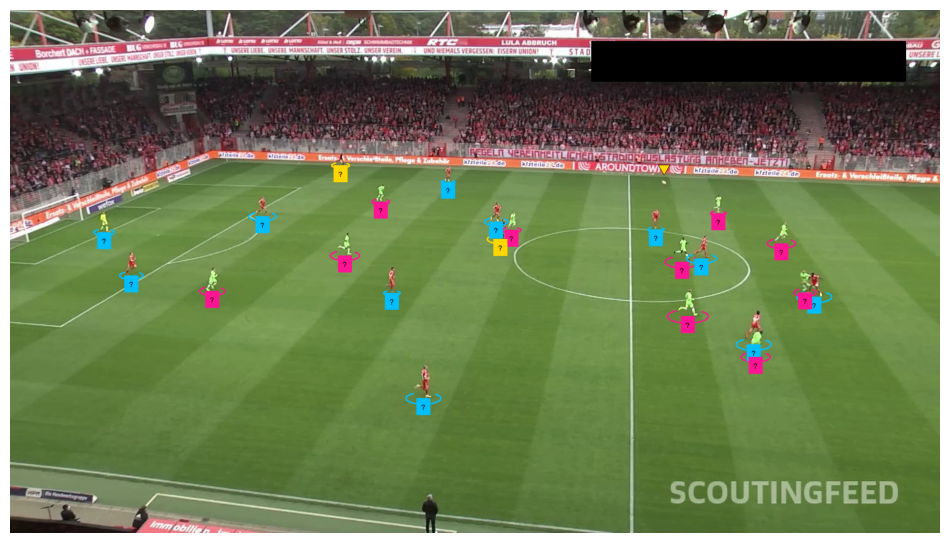

In [27]:
import cv2
import numpy as np
import supervision as sv
from trackers import ByteTrackTracker

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"

BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

# ID hiển thị: đội 0, đội 1, trọng tài 2.
palette = sv.ColorPalette.from_hex([
    "#00BFFF", "#FF1493", "#FFD700"
])

ellipse_annotator = sv.EllipseAnnotator(
    color=palette,
    thickness=2,
)
label_annotator = sv.LabelAnnotator(
    color=palette,
    text_color=sv.Color.from_hex("#000000"),
    text_position=sv.Position.BOTTOM_CENTER,
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.Color.from_hex("#FFD700"),
    base=25,
    height=21,
    outline_thickness=1,
)

tracker = ByteTrackTracker(minimum_consecutive_frames=1)

# Lấy frame mới và chạy detection đúng trên frame đó.
frame_generator = sv.get_video_frames_generator(
    SOURCE_VIDEO_PATH
)
frame = next(frame_generator)

ok, encoded_frame = cv2.imencode(".png", frame)
assert ok, "Không mã hóa được frame"

with modal.enable_output():
    with app.run():
        result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            PLAYER_DETECTION_MODEL_ID,
        )

for prediction in result.get("predictions", []):
    if "class" not in prediction and "class_name" in prediction:
        prediction["class"] = prediction["class_name"]

detections = sv.Detections.from_inference(result)

# Bóng: hiển thị bằng tam giác, không đưa vào tracker người.
ball_detections = detections[
    detections.class_id == BALL_ID
]
ball_detections.xyxy = sv.pad_boxes(
    xyxy=ball_detections.xyxy,
    px=10,
)

# Theo dõi người trước khi đổi class thành team ID.
all_detections = detections[
    detections.class_id != BALL_ID
]
all_detections = all_detections.with_nms(
    threshold=0.5,
    class_agnostic=True,
)
all_detections = tracker.update(all_detections)

goalkeepers_detections = all_detections[
    all_detections.class_id == GOALKEEPER_ID
]
players_detections = all_detections[
    all_detections.class_id == PLAYER_ID
]
referees_detections = all_detections[
    all_detections.class_id == REFEREE_ID
]

# Chỉ cắt ảnh cầu thủ để phân đội.
players_crops = [
    sv.crop_image(frame, xyxy)
    for xyxy in players_detections.xyxy
]

players_detections.class_id = np.asarray(
    team_classifier.predict(players_crops),
    dtype=int,
)

goalkeepers_detections.class_id = (
    resolve_goalkeepers_team_id(
        players_detections,
        goalkeepers_detections,
    )
)

# Tạm bỏ khỏi hình những thủ môn chưa xác định được đội.
goalkeepers_detections = goalkeepers_detections[
    goalkeepers_detections.class_id >= 0
]

referees_detections.class_id = np.full(
    len(referees_detections), 2, dtype=int
)

all_detections = sv.Detections.merge([
    players_detections,
    goalkeepers_detections,
    referees_detections,
])

all_detections.class_id = (
    all_detections.class_id.astype(int)
)

labels = [
    f"#{tracker_id}" if tracker_id >= 0 else "?"
    for tracker_id in all_detections.tracker_id
]

annotated_frame = frame.copy()

annotated_frame = ellipse_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
)
annotated_frame = label_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
    labels=labels,
)
annotated_frame = triangle_annotator.annotate(
    scene=annotated_frame,
    detections=ball_detections,
)

sv.plot_image(annotated_frame)

## pitch keypoint detection

In [28]:
FIELD_DETECTION_MODEL_ID = (
    "nguyns-workspace-do3bt/"
    "football-field-detection-f07vi-gh8mi-1-yolov8x-pose-t1"
)

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-WoDqkddFNjX0y07CTjLwiJ
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
└── ✓ Created Function extract_embeddings_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Us

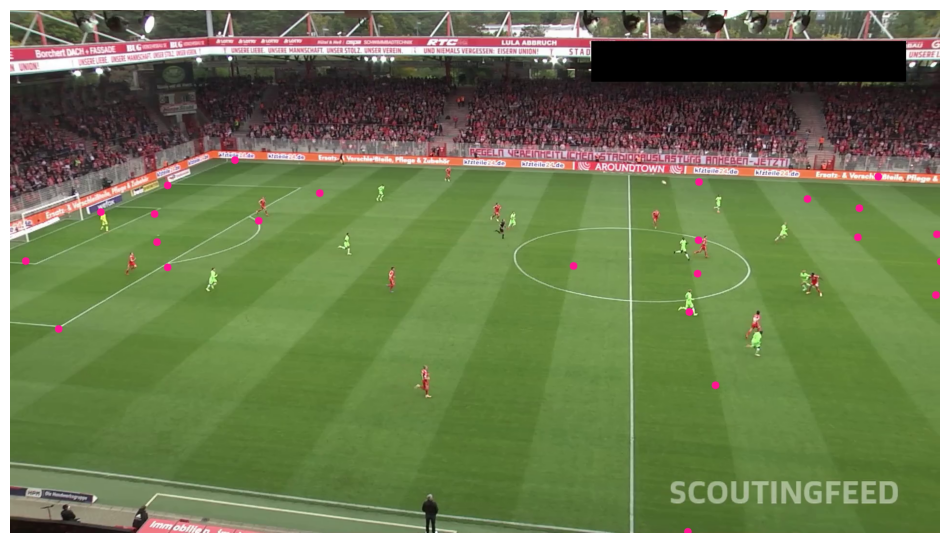

In [29]:
import cv2
import supervision as sv

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"

vertex_annotator = sv.VertexAnnotator(
    color=sv.Color.from_hex("#FF1493"),
    radius=8,
)

frame_generator = sv.get_video_frames_generator(
    SOURCE_VIDEO_PATH
)
field_frame = next(frame_generator)

ok, encoded_frame = cv2.imencode(".png", field_frame)
assert ok, "Không mã hóa được frame"

# Dùng lại helper Modal: tải model theo ID và trả kết quả inference.
with modal.enable_output():
    with app.run():
        field_result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            FIELD_DETECTION_MODEL_ID,
        )

key_points = sv.KeyPoints.from_inference(field_result)

print("Kích thước keypoints:", key_points.xy.shape)

annotated_field_frame = vertex_annotator.annotate(
    scene=field_frame.copy(),
    key_points=key_points,
)

sv.plot_image(annotated_field_frame)

**Note:** Notice that some of the keypoints detected are in incorrect
locations. These are keypoints with a low confidence level. Let's filter out these keypoints and keep only the ones the model is confident about.

## filter low confidence keypoints

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-pZOQfGe7OuzpXeJT4VVD7N
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
└── ✓ Created Function extract_embeddings_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Us

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.



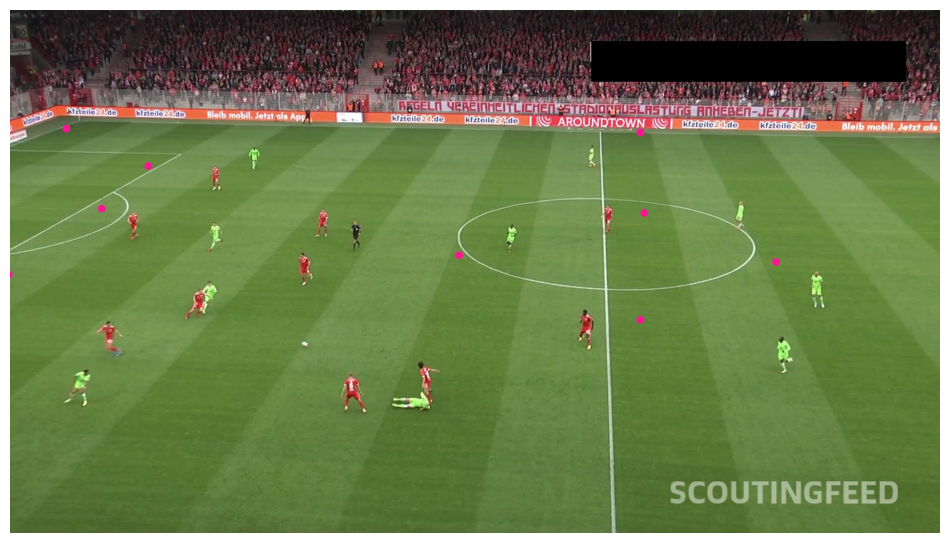

In [30]:
import cv2
import numpy as np
import supervision as sv

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"

vertex_annotator = sv.VertexAnnotator(
    color=sv.Color.from_hex("#FF1493"),
    radius=8,
)

# Lấy frame tại chỉ số 200.
frame_generator = sv.get_video_frames_generator(
    source_path=SOURCE_VIDEO_PATH,
    start=200,
)

frame = next(frame_generator)
field_frame = frame

ok, encoded_frame = cv2.imencode(".png", frame)
assert ok, "Không mã hóa được frame"

with modal.enable_output():
    with app.run():
        field_result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            FIELD_DETECTION_MODEL_ID,
        )

key_points = sv.KeyPoints.from_inference(field_result)

if len(key_points.xy) == 0:
    raise ValueError("Model không trả về keypoints cho frame 200.")

if key_points.confidence is None:
    raise ValueError("Kết quả không có confidence keypoint.")

# Giữ mask theo thứ tự 32 điểm gốc để ghép với sân chuẩn sau này.
keypoint_mask = (
    (key_points.confidence[0] > 0.5)
    & np.isfinite(key_points.xy[0]).all(axis=1)
)

frame_reference_points = key_points.xy[0][keypoint_mask]

print(
    "Số keypoints được giữ:",
    len(frame_reference_points),
    "/",
    key_points.xy.shape[1],
)

annotated_frame = frame.copy()

if len(frame_reference_points) > 0:
    frame_reference_key_points = sv.KeyPoints(
        xy=frame_reference_points[np.newaxis, ...]
    )

    annotated_frame = vertex_annotator.annotate(
        scene=annotated_frame,
        key_points=frame_reference_key_points,
    )

sv.plot_image(annotated_frame)

## project pitch lines on frame

**Note:** The [sports](https://github.com/roboflow/sports) repository contains a [`SoccerPitchConfiguration`](https://github.com/roboflow/sports/blob/06053616f1f8a8ae1fa936eb00dcdc2e4f888bb1/sports/configs/soccer.py#L6) that provides information about the real-world geometry of the soccer pitch. It also includes utilities for visualizing elements located on the pitch.

In [31]:
# Chỉ cài mã nguồn sports; phần vẽ dùng các thư viện đã có ở Colab.
!pip install -q --no-deps git+https://github.com/roboflow/sports.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


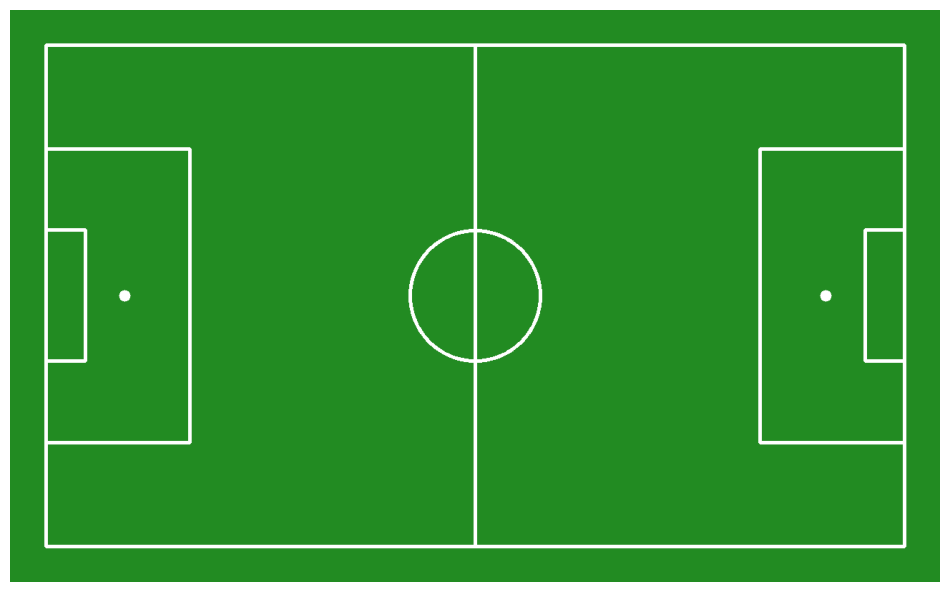

In [32]:
import supervision as sv
from sports.annotators.soccer import draw_pitch
from sports.configs.soccer import SoccerPitchConfiguration

CONFIG = SoccerPitchConfiguration()

# Sơ đồ sân chuẩn, chưa ghép lên frame video.
pitch_diagram = draw_pitch(CONFIG)

sv.plot_image(pitch_diagram)

**Note:** It's time to utilize the keypoint pairs located on the camera perspective plane and the football pitch plane. The [sports](https://github.com/roboflow/sports) repository includes a [`ViewTransformer`](https://github.com/roboflow/sports/blob/06053616f1f8a8ae1fa936eb00dcdc2e4f888bb1/sports/common/view.py#L7), which employs homography for perspective transformation.

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.



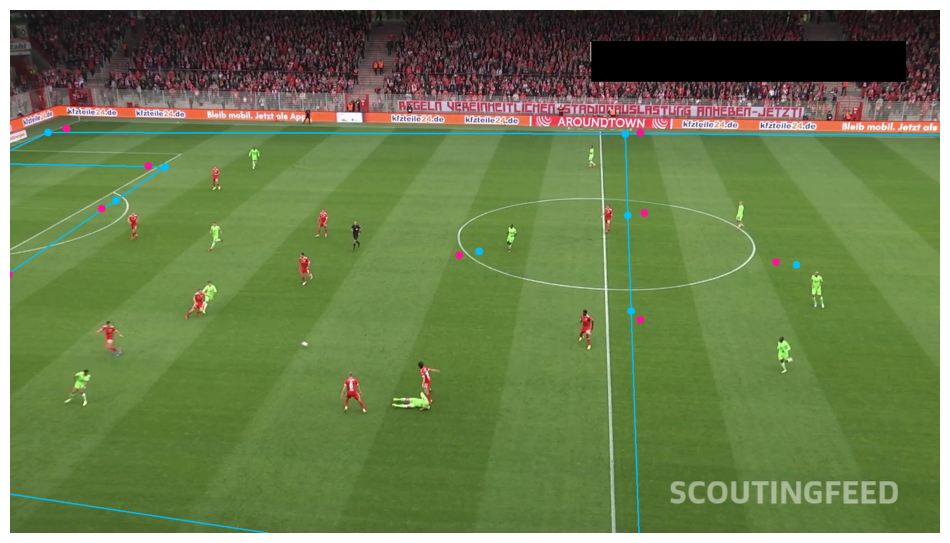

In [33]:
import numpy as np
import supervision as sv
from sports.common.view import ViewTransformer

edge_annotator = sv.EdgeAnnotator(
    color=sv.Color.from_hex("#00BFFF"),
    thickness=2,
    edges=CONFIG.edges,
)

vertex_annotator = sv.VertexAnnotator(
    color=sv.Color.from_hex("#FF1493"),
    radius=8,
)

vertex_annotator_2 = sv.VertexAnnotator(
    color=sv.Color.from_hex("#00BFFF"),
    radius=8,
)

# Dùng lại frame 200 và keypoints của cell trước.
frame = field_frame

if len(key_points.xy) != 1:
    raise ValueError("Cell này cần đúng một bộ keypoints sân.")

if key_points.confidence is None:
    raise ValueError("Kết quả không có confidence keypoint.")

pitch_all_points = np.asarray(
    CONFIG.vertices,
    dtype=np.float32,
)

if len(pitch_all_points) != key_points.xy.shape[1]:
    raise ValueError(
        "Số điểm trong CONFIG không khớp với model: "
        f"{len(pitch_all_points)} và {key_points.xy.shape[1]}"
    )

# Chọn cùng chỉ số điểm ở ảnh video và sơ đồ sân.
keypoint_mask = (
    (key_points.confidence[0] > 0.5)
    & np.isfinite(key_points.xy[0]).all(axis=1)
)

frame_reference_points = key_points.xy[0][
    keypoint_mask
].astype(np.float32)

pitch_reference_points = pitch_all_points[keypoint_mask]

if len(frame_reference_points) < 4:
    raise ValueError(
        "Chưa đủ 4 cặp điểm để tính homography: "
        f"hiện có {len(frame_reference_points)}."
    )

# Loại trường hợp toàn bộ điểm nằm trên một đường thẳng.
for name, points in [
    ("frame", frame_reference_points),
    ("pitch", pitch_reference_points),
]:
    centered_points = points - points.mean(axis=0)
    if np.linalg.matrix_rank(centered_points) < 2:
        raise ValueError(
            f"Các điểm {name} bị thẳng hàng, "
            "không đủ để tính homography."
        )

# Chiều biến đổi: sân chuẩn → ảnh camera.
transformer = ViewTransformer(
    source=pitch_reference_points,
    target=frame_reference_points,
)

frame_all_points = transformer.transform_points(
    points=pitch_all_points
)

if not np.isfinite(frame_all_points).all():
    raise ValueError("Điểm chiếu chứa NaN/Infinity.")

frame_all_key_points = sv.KeyPoints(
    xy=frame_all_points[np.newaxis, ...]
)

frame_reference_key_points = sv.KeyPoints(
    xy=frame_reference_points[np.newaxis, ...]
)

annotated_frame = frame.copy()

annotated_frame = edge_annotator.annotate(
    scene=annotated_frame,
    key_points=frame_all_key_points,
)
annotated_frame = vertex_annotator_2.annotate(
    scene=annotated_frame,
    key_points=frame_all_key_points,
)
annotated_frame = vertex_annotator.annotate(
    scene=annotated_frame,
    key_points=frame_reference_key_points,
)

sv.plot_image(annotated_frame)

## project ball, players and referies on pitch

In [34]:
# Dùng lại classifier đã tạo từ UMAP/KMeans trước đó.
if "team_classifier" not in globals():
    raise RuntimeError(
        "Chưa có team_classifier. "
        "Hãy chạy lại cell tạo ModalTeamClassifier "
        "sau khi UMAP/KMeans đã được fit."
    )

print("Dùng lại team_classifier hiện có.")
print("Không thu thập crops hoặc fit lại.")

Dùng lại team_classifier hiện có.
Không thu thập crops hoặc fit lại.


In [35]:
import cv2
import numpy as np
import supervision as sv
from typing import Optional

from sports.annotators.soccer import draw_pitch
from sports.configs.soccer import SoccerPitchConfiguration


def draw_pitch_voronoi_diagram_2(
    config: SoccerPitchConfiguration,
    team_1_xy: np.ndarray,
    team_2_xy: np.ndarray,
    team_1_color: sv.Color = sv.Color.from_hex("#00BFFF"),
    team_2_color: sv.Color = sv.Color.from_hex("#FF1493"),
    opacity: float = 0.5,
    padding: int = 50,
    scale: float = 0.1,
    pitch: Optional[np.ndarray] = None,
) -> np.ndarray:
    """
    Vẽ vùng gần cầu thủ của mỗi đội với chuyển màu mềm.
    Đầu vào là tọa độ trên sân chuẩn, chưa nhân scale.
    """
    if not 0 <= opacity <= 1:
        raise ValueError("opacity phải nằm trong [0, 1].")

    if scale <= 0 or padding < 0:
        raise ValueError("scale phải > 0 và padding phải >= 0.")

    if pitch is None:
        pitch = draw_pitch(
            config=config,
            padding=padding,
            scale=scale,
        )

    def prepare_points(points):
        points = np.asarray(points, dtype=np.float32)

        if points.size == 0:
            return np.empty((0, 2), dtype=np.float32)

        if points.ndim != 2 or points.shape[1] != 2:
            raise ValueError("Tọa độ mỗi đội phải có dạng (N, 2).")

        return points[np.isfinite(points).all(axis=1)]

    team_1_xy = prepare_points(team_1_xy)
    team_2_xy = prepare_points(team_2_xy)

    # Không đủ dữ liệu hai đội: giữ sơ đồ sân,
    # không tô toàn sân thành vùng của một đội.
    if len(team_1_xy) == 0 or len(team_2_xy) == 0:
        return pitch.copy()

    expected_shape = (
        int(config.width * scale) + 2 * padding,
        int(config.length * scale) + 2 * padding,
    )

    if pitch.shape[:2] != expected_shape:
        raise ValueError(
            "Kích thước pitch không khớp config/scale/padding: "
            f"{pitch.shape[:2]} != {expected_shape}"
        )

    height, width = pitch.shape[:2]

    y_grid, x_grid = np.indices(
        (height, width),
        dtype=np.float32,
    )
    x_grid -= padding
    y_grid -= padding

    def nearest_distance(points):
        # Cập nhật từng cầu thủ để tránh tạo mảng (N, H, W).
        min_squared_distance = np.full(
            (height, width),
            np.inf,
            dtype=np.float32,
        )

        for x, y in points:
            squared_distance = (
                (x * scale - x_grid) ** 2
                + (y * scale - y_grid) ** 2
            )
            np.minimum(
                min_squared_distance,
                squared_distance,
                out=min_squared_distance,
            )

        return np.sqrt(min_squared_distance)

    distance_1 = nearest_distance(team_1_xy)
    distance_2 = nearest_distance(team_2_xy)

    ratio = distance_2 / np.maximum(
        distance_1 + distance_2,
        1e-5,
    )

    blend = (
        np.tanh((ratio - 0.5) * 15) * 0.5 + 0.5
    )[..., np.newaxis]

    color_1 = np.asarray(
        team_1_color.as_bgr(),
        dtype=np.float32,
    )
    color_2 = np.asarray(
        team_2_color.as_bgr(),
        dtype=np.float32,
    )

    voronoi = (
        blend * color_1 + (1 - blend) * color_2
    ).astype(np.uint8)

    overlay = cv2.addWeighted(
        voronoi,
        opacity,
        pitch,
        1 - opacity,
        0,
    )

    # Chỉ tô bên trong sân, giữ nguyên phần padding.
    output = pitch.copy()

    x_start = padding
    y_start = padding
    x_end = padding + int(config.length * scale)
    y_end = padding + int(config.width * scale)

    output[y_start:y_end, x_start:x_end] = (
        overlay[y_start:y_end, x_start:x_end]
    )

    return output

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-vpbKPMPv3I4LAj6CSUgtZb
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
└── ✓ Created Function extract_embeddings_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` configuration does not support SAM model. Us

[modal-client] 2026-10-30T06:20:17+0000 Timed out waiting for final app logs.


✓ App completed. View run at 
https://modal.com/apps/luluchi19/main/ap-YeTBTCK67Kxdg8rSDEJ0e7


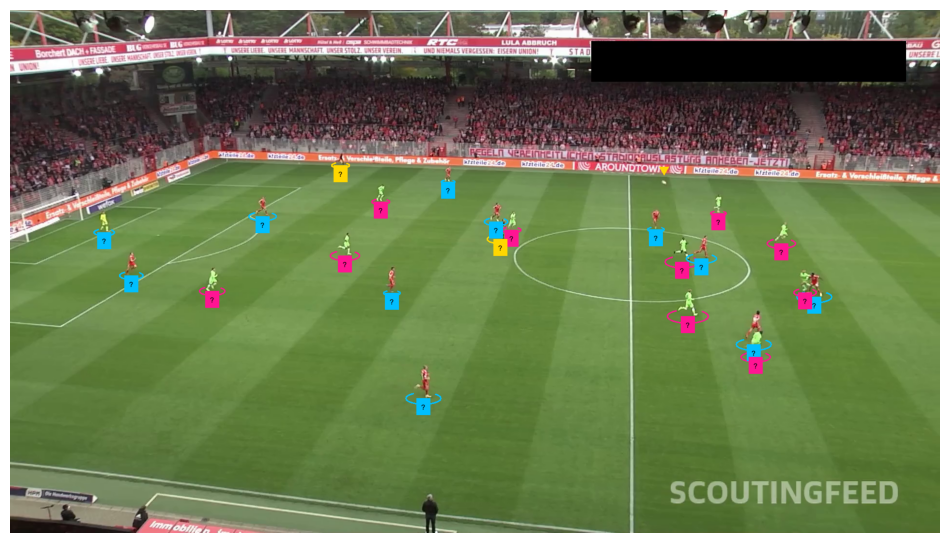

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.

/usr/local/lib/python3.13/dist-packages/supervision/key_points/core.py:377: SupervisionWarnings:

'KeyPoints.confidence' is deprecated since 0.29.0 and will be removed in 0.32.0. Use 'KeyPoints.keypoint_confidence' instead.



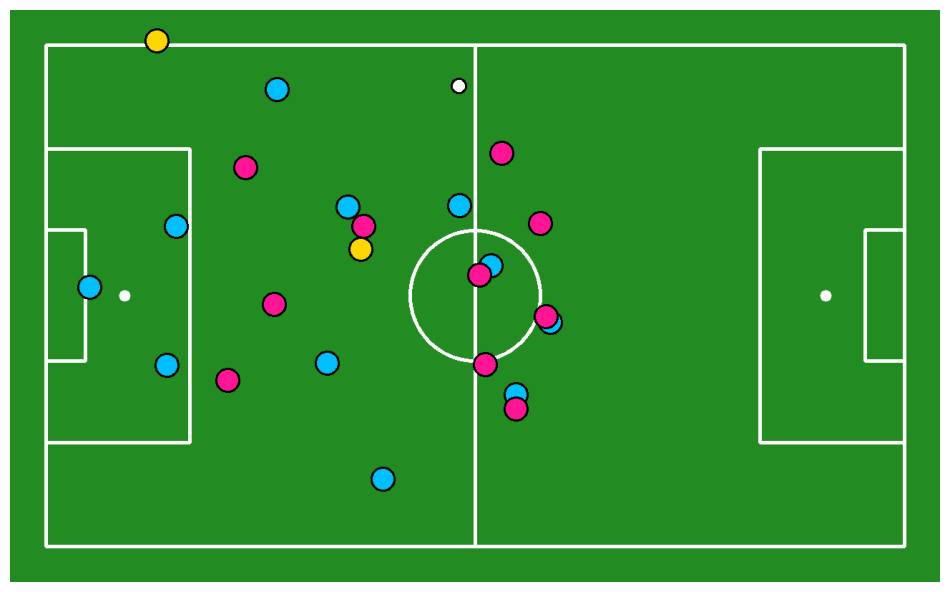

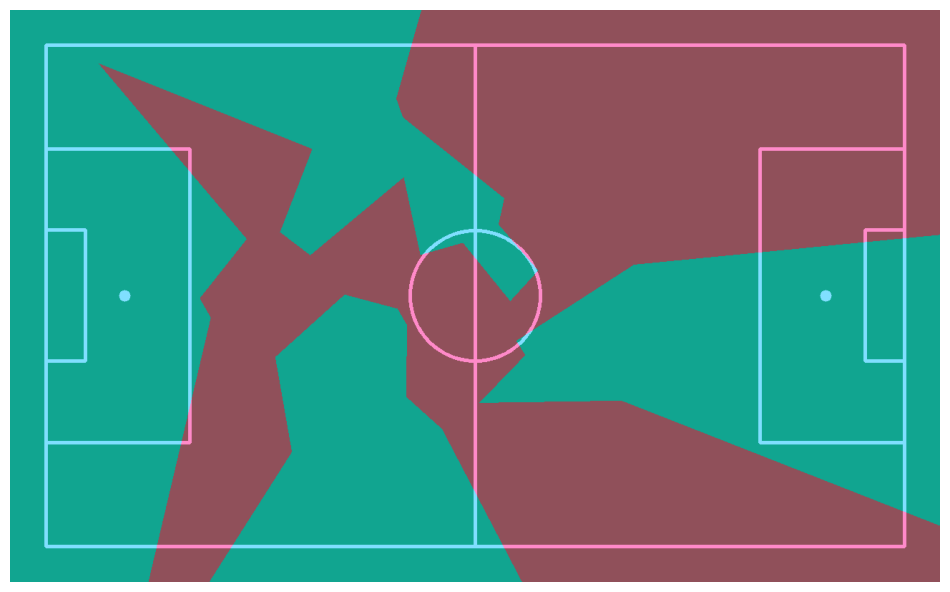

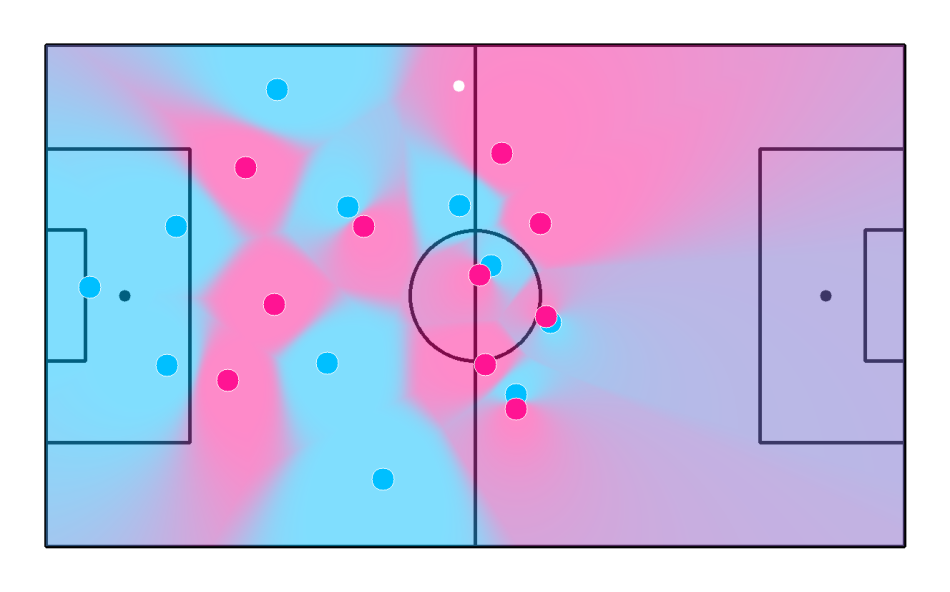

In [37]:
import supervision as sv
import cv2
import numpy as np
from trackers import ByteTrackTracker

from sports.annotators.soccer import (
    draw_pitch,
    draw_points_on_pitch,
    draw_pitch_voronoi_diagram
)

SOURCE_VIDEO_PATH = "/content/121364_0.mp4"
BALL_ID = 0
GOALKEEPER_ID = 1
PLAYER_ID = 2
REFEREE_ID = 3

ellipse_annotator = sv.EllipseAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    thickness=2
)
label_annotator = sv.LabelAnnotator(
    color=sv.ColorPalette.from_hex(['#00BFFF', '#FF1493', '#FFD700']),
    text_color=sv.Color.from_hex('#000000'),
    text_position=sv.Position.BOTTOM_CENTER
)
triangle_annotator = sv.TriangleAnnotator(
    color=sv.Color.from_hex('#FFD700'),
    base=20, height=17
)

tracker = ByteTrackTracker(minimum_consecutive_frames=1)

frame_generator = sv.get_video_frames_generator(SOURCE_VIDEO_PATH)
frame = next(frame_generator)

# ball, goalkeeper, player, referee detection

ok, encoded_frame = cv2.imencode(".png", frame)
assert ok, "Không mã hóa được frame"

# Cả hai model xử lý cùng một ảnh.
with modal.enable_output():
    with app.run():
        player_result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            PLAYER_DETECTION_MODEL_ID,
        )
        field_result = detect_frame_modal.remote(
            encoded_frame.tobytes(),
            FIELD_DETECTION_MODEL_ID,
        )

for prediction in player_result.get("predictions", []):
    if "class" not in prediction and "class_name" in prediction:
        prediction["class"] = prediction["class_name"]

detections = sv.Detections.from_inference(player_result)

ball_detections = detections[detections.class_id == BALL_ID]
ball_detections.xyxy = sv.pad_boxes(xyxy=ball_detections.xyxy, px=10)

all_detections = detections[detections.class_id != BALL_ID]
all_detections = all_detections.with_nms(threshold=0.5, class_agnostic=True)
all_detections = tracker.update(all_detections)

goalkeepers_detections = all_detections[all_detections.class_id == GOALKEEPER_ID]
players_detections = all_detections[all_detections.class_id == PLAYER_ID]
referees_detections = all_detections[all_detections.class_id == REFEREE_ID]

# team assignment

players_crops = [sv.crop_image(frame, xyxy) for xyxy in players_detections.xyxy]
players_detections.class_id = team_classifier.predict(players_crops)

goalkeepers_detections.class_id = resolve_goalkeepers_team_id(
    players_detections, goalkeepers_detections)
goalkeepers_detections = goalkeepers_detections[
    goalkeepers_detections.class_id >= 0
]

referees_detections.class_id -= 1

all_detections = sv.Detections.merge([
    players_detections, goalkeepers_detections, referees_detections])

# frame visualization

labels = [
    f"#{tracker_id}" if tracker_id >= 0 else "?"
    for tracker_id in all_detections.tracker_id
]

all_detections.class_id = all_detections.class_id.astype(int)

annotated_frame = frame.copy()
annotated_frame = ellipse_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections)
annotated_frame = label_annotator.annotate(
    scene=annotated_frame,
    detections=all_detections,
    labels=labels)
annotated_frame = triangle_annotator.annotate(
    scene=annotated_frame,
    detections=ball_detections)

sv.plot_image(annotated_frame)

players_detections = sv.Detections.merge([
    players_detections, goalkeepers_detections
])

# detect pitch key points

key_points = sv.KeyPoints.from_inference(field_result)

# project ball, players and referies on pitch

if len(key_points.xy) != 1 or key_points.confidence is None:
    raise ValueError("Không có đúng một bộ keypoints kèm confidence.")

pitch_vertices = np.asarray(CONFIG.vertices, dtype=np.float32)

if len(pitch_vertices) != key_points.xy.shape[1]:
    raise ValueError("CONFIG.vertices không khớp số keypoints của model.")

keypoint_mask = (
    (key_points.confidence[0] > 0.5)
    & np.isfinite(key_points.xy[0]).all(axis=1)
)

frame_reference_points = key_points.xy[0][
    keypoint_mask
].astype(np.float32)

pitch_reference_points = pitch_vertices[keypoint_mask]

if len(frame_reference_points) < 4:
    raise ValueError("Chưa đủ 4 cặp keypoints để tính homography.")

for points in (frame_reference_points, pitch_reference_points):
    if np.linalg.matrix_rank(points - points.mean(axis=0)) < 2:
        raise ValueError("Các điểm tham chiếu bị thẳng hàng.")

# Đúng chiều cho radar: ảnh camera → sân chuẩn.
transformer = ViewTransformer(
    source=frame_reference_points,
    target=pitch_reference_points,
)

def project_points_safely(points):
    points = np.asarray(points, dtype=np.float32).reshape(-1, 2)

    if len(points) == 0:
        return np.empty((0, 2), dtype=np.float32)

    projected = transformer.transform_points(points=points)

    if not np.isfinite(projected).all():
        raise ValueError("Phép chiếu trả NaN/Infinity.")

    return projected

frame_ball_xy = ball_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
pitch_ball_xy = project_points_safely(frame_ball_xy)

players_xy = players_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
pitch_players_xy = project_points_safely(players_xy)

referees_xy = referees_detections.get_anchors_coordinates(sv.Position.BOTTOM_CENTER)
pitch_referees_xy = project_points_safely(referees_xy)

# visualize video game-style radar view

annotated_frame = draw_pitch(CONFIG)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_ball_xy,
    face_color=sv.Color.WHITE,
    edge_color=sv.Color.BLACK,
    radius=10,
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_players_xy[players_detections.class_id == 0],
    face_color=sv.Color.from_hex('00BFFF'),
    edge_color=sv.Color.BLACK,
    radius=16,
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_players_xy[players_detections.class_id == 1],
    face_color=sv.Color.from_hex('FF1493'),
    edge_color=sv.Color.BLACK,
    radius=16,
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_referees_xy,
    face_color=sv.Color.from_hex('FFD700'),
    edge_color=sv.Color.BLACK,
    radius=16,
    pitch=annotated_frame)

sv.plot_image(annotated_frame)

# visualize voronoi diagram

team_0_xy = pitch_players_xy[players_detections.class_id == 0]
team_1_xy = pitch_players_xy[players_detections.class_id == 1]

annotated_frame = draw_pitch(CONFIG)

if len(team_0_xy) > 0 and len(team_1_xy) > 0:
    annotated_frame = draw_pitch_voronoi_diagram(
        config=CONFIG,
        team_1_xy=team_0_xy,
        team_2_xy=team_1_xy,
        team_1_color=sv.Color.from_hex("#00BFFF"),
        team_2_color=sv.Color.from_hex("#FF1493"),
        pitch=annotated_frame,
    )
else:
    print("Không đủ dữ liệu hai đội để vẽ Voronoi.")

sv.plot_image(annotated_frame)

# visualize voronoi diagram with blend

annotated_frame = draw_pitch(
    config=CONFIG,
    background_color=sv.Color.WHITE,
    line_color=sv.Color.BLACK
)
annotated_frame = draw_pitch_voronoi_diagram_2(
    config=CONFIG,
    team_1_xy=pitch_players_xy[players_detections.class_id == 0],
    team_2_xy=pitch_players_xy[players_detections.class_id == 1],
    team_1_color=sv.Color.from_hex('00BFFF'),
    team_2_color=sv.Color.from_hex('FF1493'),
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_ball_xy,
    face_color=sv.Color.WHITE,
    edge_color=sv.Color.WHITE,
    radius=8,
    thickness=1,
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_players_xy[players_detections.class_id == 0],
    face_color=sv.Color.from_hex('00BFFF'),
    edge_color=sv.Color.WHITE,
    radius=16,
    thickness=1,
    pitch=annotated_frame)
annotated_frame = draw_points_on_pitch(
    config=CONFIG,
    xy=pitch_players_xy[players_detections.class_id == 1],
    face_color=sv.Color.from_hex('FF1493'),
    edge_color=sv.Color.WHITE,
    radius=16,
    thickness=1,
    pitch=annotated_frame)

sv.plot_image(annotated_frame)

## ball tracking

In [38]:
@app.function(
    image=modal_image,
    gpu="L40S",
    secrets=[runtime_secrets],
    volumes={"/storage": video_volume},
    timeout=3600,
)
def track_ball_modal(
    player_model_id: str,
    field_model_id: str,
    pitch_vertices: list,
    max_frames: int = 120,
):
    import os
    from pathlib import Path
    from datetime import datetime

    import cv2
    import numpy as np
    import supervision as sv
    import onnxruntime as ort
    from tqdm import tqdm

    os.environ.pop("ONNXRUNTIME_EXECUTION_PROVIDERS", None)

    if hasattr(ort, "preload_dlls"):
        ort.preload_dlls()

    try:
        from inference import get_model

        video_volume.reload()
        video_path = "/storage/inputs/121364_0.mp4"

        if not Path(video_path).is_file():
            raise FileNotFoundError(
                "Video chưa có trong football-ai-videos/inputs."
            )

        player_model = get_model(
            model_id=player_model_id,
            api_key=os.environ["ROBOFLOW_API_KEY"],
        )
        field_model = get_model(
            model_id=field_model_id,
            api_key=os.environ["ROBOFLOW_API_KEY"],
        )

        vertices = np.asarray(pitch_vertices, dtype=np.float32)

        video_info = sv.VideoInfo.from_video_path(video_path)
        frame_generator = sv.get_video_frames_generator(video_path)

        total = video_info.total_frames
        if max_frames > 0:
            total = min(total, max_frames)

        # Một phần tử cho mỗi frame đã xử lý.
        path_raw = []
        homography_ok = []

        def to_dict(result):
            return (
                result.model_dump(mode="json", by_alias=True)
                if hasattr(result, "model_dump")
                else result
            )

        for index, frame in enumerate(
            tqdm(frame_generator, total=total, desc="Ball projection")
        ):
            if max_frames > 0 and index >= max_frames:
                break

            player_result = to_dict(
                player_model.infer(frame, confidence=0.3)[0]
            )
            detections = sv.Detections.from_inference(player_result)

            ball_detections = detections[
                detections.class_id == 0
            ]

            field_result = to_dict(
                field_model.infer(frame, confidence=0.3)[0]
            )
            key_points = sv.KeyPoints.from_inference(field_result)

            projected = np.empty((0, 2), dtype=np.float32)
            valid_homography = False

            if (
                len(key_points.xy) == 1
                and key_points.confidence is not None
            ):
                if key_points.xy.shape[1] != len(vertices):
                    raise ValueError(
                        "Số keypoints model không khớp CONFIG.vertices."
                    )

                mask = (
                    (key_points.confidence[0] > 0.5)
                    & np.isfinite(key_points.xy[0]).all(axis=1)
                )

                source = key_points.xy[0][mask].astype(np.float32)
                target = vertices[mask]

                if (
                    len(source) >= 4
                    and np.linalg.matrix_rank(
                        source - source.mean(axis=0)
                    ) >= 2
                    and np.linalg.matrix_rank(
                        target - target.mean(axis=0)
                    ) >= 2
                ):
                    # Đích dùng đơn vị CONFIG; ngưỡng RANSAC
                    # cũng theo đơn vị đó.
                    H, inliers = cv2.findHomography(
                        source,
                        target,
                        method=cv2.RANSAC,
                        ransacReprojThreshold=0.01 * max(
                            np.ptp(vertices[:, 0]),
                            np.ptp(vertices[:, 1]),
                        ),
                    )

                    valid_homography = (
                        H is not None
                        and np.isfinite(H).all()
                        and inliers is not None
                        and int(inliers.sum()) >= 4
                    )

                    if valid_homography and len(ball_detections) > 0:
                        # Giữ cách lấy bottom-center như notebook.
                        # Không pad box trước khi đo vị trí bóng:
                        # padding sẽ làm dịch bottom-center xuống dưới.
                        ball_xy = ball_detections.get_anchors_coordinates(
                            sv.Position.BOTTOM_CENTER
                        ).astype(np.float32)

                        projected = cv2.perspectiveTransform(
                            ball_xy.reshape(-1, 1, 2),
                            H,
                        ).reshape(-1, 2)

                        projected = projected[
                            np.isfinite(projected).all(axis=1)
                        ]

            path_raw.append(projected.tolist())
            homography_ok.append(bool(valid_homography))

        output_dir = Path("/storage/outputs")
        output_dir.mkdir(parents=True, exist_ok=True)

        # Lưu dạng phẳng + offsets, không cần object array/pickle.
        lengths = np.asarray(
            [len(points) for points in path_raw],
            dtype=np.int64,
        )
        offsets = np.concatenate(([0], np.cumsum(lengths)))
        flat_points = np.asarray(
            [point for points in path_raw for point in points],
            dtype=np.float32,
        ).reshape(-1, 2)

        output_path = output_dir / (
            datetime.now().strftime("ball-path-%Y%m%d-%H%M%S")
            + ".npz"
        )

        np.savez_compressed(
            output_path,
            points=flat_points,
            offsets=offsets,
            homography_ok=np.asarray(homography_ok),
            fps=video_info.fps,
        )
        video_volume.commit()

        return {
            "path": path_raw,
            "homography_ok": homography_ok,
            "fps": float(video_info.fps),
            "saved_file": str(output_path),
        }

    except Exception as exc:
        raise RuntimeError(
            f"{type(exc).__name__}: {exc}"
        ) from None

In [39]:
with modal.enable_output():
    with app.run():
        ball_tracking_result = track_ball_modal.remote(
            player_model_id=PLAYER_DETECTION_MODEL_ID,
            field_model_id=FIELD_DETECTION_MODEL_ID,
            pitch_vertices=np.asarray(CONFIG.vertices).tolist(),
            max_frames=0,
        )

# Giữ tên path_raw cho các cell sau.
path_raw = [
    np.asarray(points, dtype=np.float32).reshape(-1, 2)
    for points in ball_tracking_result["path"]
]

print("Số frame xử lý:", len(path_raw))
print(
    "Số frame có homography hợp lệ:",
    sum(ball_tracking_result["homography_ok"]),
)
print(
    "Số frame có tọa độ bóng:",
    sum(len(points) > 0 for points in path_raw),
)
print("Đã lưu:", ball_tracking_result["saved_file"])

✓ Initialized. View run at 
https://modal.com/apps/luluchi19/main/ap-hBNKJoIw2LyuZAvlRoVt6P
✓ Created objects.
├── ✓ Created Function check_player_model.
├── ✓ Created Function detect_frame_modal.
├── ✓ Created Function collect_player_crops_modal.
├── ✓ Created Function extract_embeddings_modal.
└── ✓ Created Function track_ball_modal.
/usr/local/lib/python3.13/site-packages/inference/core/env.py:345: InferenceDeprecationWarning: CORE_MODEL_GAZE_ENABLED is True: POST /gaze/gaze_detection is registered as a deprecation stub returning HTTP 410 Gone. The stub and this flag will be removed end of Q2 2026. Set CORE_MODEL_GAZE_ENABLED=False to disable it now.
  warnings.warn(
/usr/local/lib/python3.13/site-packages/pydantic/_internal/_fields.py:198: UserWarning: Field name "schema" in "WorkflowsBlocksSchemaDescription" shadows an attribute in parent "BaseModel"
  warnings.warn(
/usr/local/lib/python3.13/site-packages/inference/models/utils.py:564: ModelDependencyMissing: Your `inference` con

[modal-client] 2026-10-30T06:22:09+0000 Timed out waiting for final app logs.


✓ App completed. View run at 
https://modal.com/apps/luluchi19/main/ap-hBNKJoIw2LyuZAvlRoVt6P
Số frame xử lý: 750
Số frame có homography hợp lệ: 750
Số frame có tọa độ bóng: 499
Đã lưu: /storage/outputs/ball-path-20261030-062159.npz


In [40]:
import numpy as np

path = []

missing_count = 0
ambiguous_count = 0
invalid_count = 0

for coordinates in path_raw:
    coordinates = np.asarray(
        coordinates,
        dtype=np.float32,
    ).reshape(-1, 2)

    if len(coordinates) == 0:
        missing_count += 1
        point = np.empty(0, dtype=np.float32)

    elif len(coordinates) >= 2:
        ambiguous_count += 1
        point = np.empty(0, dtype=np.float32)

    elif not np.isfinite(coordinates[0]).all():
        invalid_count += 1
        point = np.empty(0, dtype=np.float32)

    else:
        point = coordinates[0].copy()  # shape (2,)

    path.append(point)

assert len(path) == len(path_raw)

print("Tổng frame:", len(path))
print("Frame giữ một vị trí bóng:", sum(p.size == 2 for p in path))
print("Frame không có vị trí:", missing_count)
print("Frame nhiều detection bóng:", ambiguous_count)
print("Frame có tọa độ không hợp lệ:", invalid_count)

Tổng frame: 750
Frame giữ một vị trí bóng: 493
Frame không có vị trí: 251
Frame nhiều detection bóng: 6
Frame có tọa độ không hợp lệ: 0


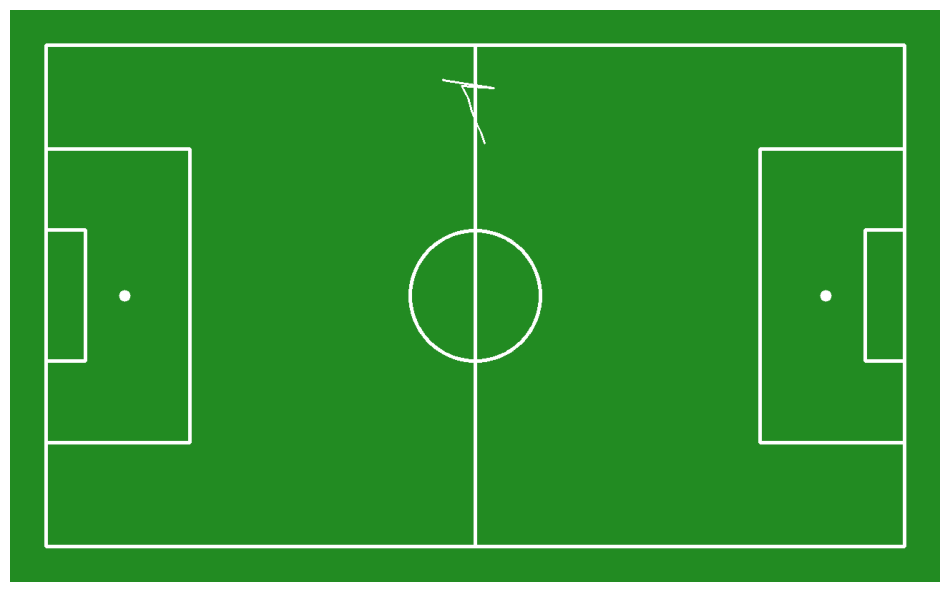

In [41]:
import supervision as sv
from sports.annotators.soccer import (
    draw_pitch,
    draw_paths_on_pitch,
)

def split_path_at_missing_positions(positions):
    segments = []
    current_segment = []

    for position in positions:
        point = np.asarray(position, dtype=np.float32).reshape(-1)

        if point.size == 2 and np.isfinite(point).all():
            current_segment.append(point)
        else:
            if len(current_segment) >= 2:
                segments.append(
                    np.asarray(current_segment, dtype=np.float32)
                )
            current_segment = []

    if len(current_segment) >= 2:
        segments.append(
            np.asarray(current_segment, dtype=np.float32)
        )

    return segments


path_segments = split_path_at_missing_positions(path)

annotated_frame = draw_pitch(CONFIG)

if path_segments:
    annotated_frame = draw_paths_on_pitch(
        config=CONFIG,
        paths=path_segments,
        color=sv.Color.WHITE,
        pitch=annotated_frame,
    )
else:
    print("Chưa có đoạn gồm ít nhất hai frame liên tiếp có bóng.")

sv.plot_image(annotated_frame)

In [42]:
from typing import List, Optional
import numpy as np

def replace_outliers_based_on_distance(
    positions: List[np.ndarray],
    distance_threshold: float,
    max_gap_frames: Optional[int] = None,
) -> List[np.ndarray]:
    """
    distance_threshold:
        Khoảng cách tối đa tới vị trí được chấp nhận gần nhất,
        cùng đơn vị với CONFIG.vertices.

    max_gap_frames:
        Nếu quá số frame này chưa chấp nhận vị trí mới,
        bỏ tham chiếu cũ và cho phép khởi tạo lại.
        None giữ cách so sánh của notebook gốc.
    """
    if not np.isfinite(distance_threshold) or distance_threshold <= 0:
        raise ValueError("distance_threshold phải hữu hạn và > 0.")

    if max_gap_frames is not None and max_gap_frames < 1:
        raise ValueError("max_gap_frames phải >= 1 hoặc None.")

    last_valid_position = None
    last_valid_index = None
    cleaned_positions = []

    for frame_index, position in enumerate(positions):
        point = np.asarray(
            position,
            dtype=np.float32,
        ).reshape(-1)

        if point.size == 0:
            cleaned_positions.append(
                np.empty(0, dtype=np.float32)
            )
            continue

        if point.size != 2:
            raise ValueError(
                f"Frame {frame_index}: cần một điểm (x, y)."
            )

        if not np.isfinite(point).all():
            cleaned_positions.append(
                np.empty(0, dtype=np.float32)
            )
            continue

        if (
            max_gap_frames is not None
            and last_valid_index is not None
            and frame_index - last_valid_index > max_gap_frames
        ):
            last_valid_position = None

        accept = (
            last_valid_position is None
            or np.linalg.norm(point - last_valid_position)
            <= distance_threshold
        )

        if accept:
            cleaned_positions.append(point.copy())
            last_valid_position = point.copy()
            last_valid_index = frame_index
        else:
            cleaned_positions.append(
                np.empty(0, dtype=np.float32)
            )

    return cleaned_positions

In [43]:
MAX_DISTANCE_THRESHOLD = 500

# Giữ bản trước lọc để có thể thử lại ngưỡng,
# tránh lọc chồng lên kết quả đã lọc.
if "path_before_distance_filter" not in globals():
    path_before_distance_filter = [
        point.copy() for point in path
    ]

path = replace_outliers_based_on_distance(
    positions=path_before_distance_filter,
    distance_threshold=MAX_DISTANCE_THRESHOLD,
    max_gap_frames=None,  # Giữ hành vi so sánh của code gốc.
)

before_count = sum(
    point.size == 2
    for point in path_before_distance_filter
)
after_count = sum(point.size == 2 for point in path)

print("Số vị trí trước lọc:", before_count)
print("Số vị trí sau lọc:", after_count)
print("Số vị trí bị loại:", before_count - after_count)
print("Kích thước sân trong CONFIG:", CONFIG.length, CONFIG.width)

Số vị trí trước lọc: 493
Số vị trí sau lọc: 352
Số vị trí bị loại: 141
Kích thước sân trong CONFIG: 12000 7000


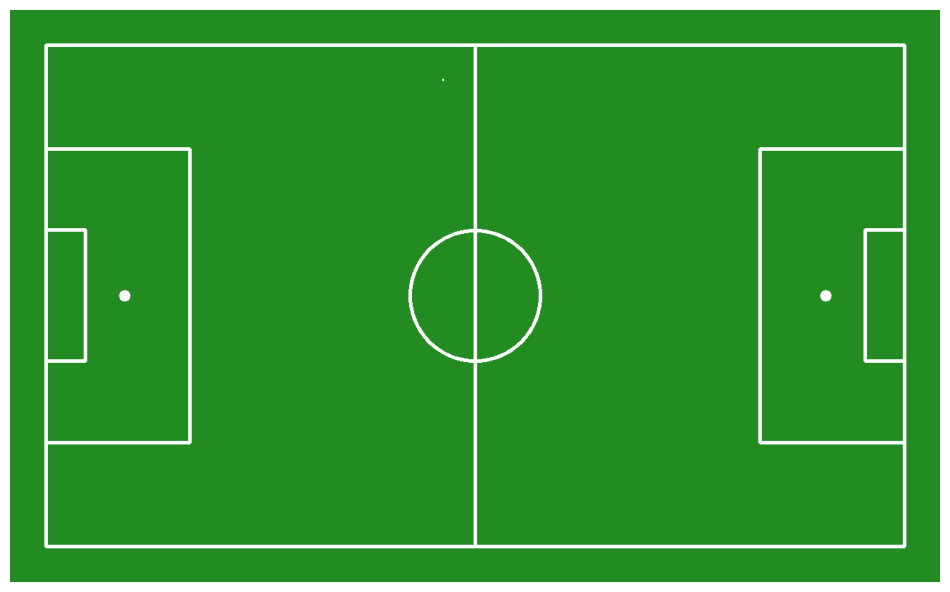

In [44]:
from sports.annotators.soccer import (
    draw_pitch,
    draw_paths_on_pitch,
)

# Dùng helper đã định nghĩa ở cell trước:
# ngắt đường tại các vị trí rỗng/bị loại.
cleaned_segments = split_path_at_missing_positions(path)

annotated_frame = draw_pitch(CONFIG)

if cleaned_segments:
    annotated_frame = draw_paths_on_pitch(
        config=CONFIG,
        paths=cleaned_segments,
        color=sv.Color.WHITE,
        pitch=annotated_frame,
    )
else:
    print("Không có đoạn hợp lệ gồm ít nhất hai frame liên tiếp.")

sv.plot_image(annotated_frame)